# AIRLINE ANALYTICS PROJECT

# Name = Vishwajit Vilas Mali


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully")

Libraries imported successfully


In [3]:
airports = pd.read_csv("C:/vishu/main project/Airline_Analytics_Complete_Dataset/airports.csv")
bookings = pd.read_csv("C:/vishu/main project/Airline_Analytics_Complete_Dataset/bookings.csv")
flights = pd.read_csv("C:/vishu/main project/Airline_Analytics_Complete_Dataset/flights.csv")
satisfaction = pd.read_csv("C:/vishu/main project/Airline_Analytics_Complete_Dataset/satisfaction.csv")
print("all datasets loaded successfully")

all datasets loaded successfully


In [4]:
print(airports.shape)
print(bookings.shape)
print(flights.shape)
print(satisfaction.shape)

(12, 3)
(1800, 9)
(1200, 14)
(400, 7)


In [5]:
print(airports.head())
print(bookings.head())
print(flights.head())
print(satisfaction.head())

  Airport_Code       City Country
0          BOM     Mumbai   India
1          DEL      Delhi   India
2          BLR  Bengaluru   India
3          HYD  Hyderabad   India
4          MAA    Chennai   India
  Booking_ID Flight_ID Passenger_ID Booking_Date Travel_Class  \
0   BK000001   FL00181       P00084   2025-02-04     Business   
1   BK000002   FL00336       P00460   2025-08-26     Business   
2   BK000003   FL00488       P00026   2025-11-05      Economy   
3   BK000004   FL00047       P00849   2025-08-11      Economy   
4   BK000005   FL00416       P00819   2025-08-31      Economy   

   Ticket_Price_INR  Baggage_KG Booking_Channel Booking_Status  
0             29427           7    Travel Agent      Confirmed  
1             18749           7         Website      Confirmed  
2              4106          15         Website      Confirmed  
3              9085          25    Travel Agent      Confirmed  
4              9922          25             App      Confirmed  
  Flight_ID Fli

In [6]:
flights.info()
bookings.info()
airports.info()
satisfaction.info()

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Flight_ID            1200 non-null   str    
 1   Flight_Date          1200 non-null   str    
 2   Airline              1200 non-null   str    
 3   Origin               1200 non-null   str    
 4   Destination          1200 non-null   str    
 5   Scheduled_Departure  1200 non-null   str    
 6   Actual_Departure     1151 non-null   str    
 7   Departure_Delay_Min  1151 non-null   float64
 8   Arrival_Delay_Min    1151 non-null   float64
 9   Status               1200 non-null   str    
 10  Cancellation_Reason  49 non-null     str    
 11  Delay_Reason         401 non-null    str    
 12  Distance_KM          1200 non-null   int64  
 13  Aircraft_Capacity    1200 non-null   int64  
dtypes: float64(2), int64(2), str(10)
memory usage: 206.2 KB
<class 'pandas.DataFrame'>
RangeIndex: 1800

# checking Missing Values

In [7]:
print("flights Missing Values")
print(flights.isnull().sum())

flights Missing Values
Flight_ID                 0
Flight_Date               0
Airline                   0
Origin                    0
Destination               0
Scheduled_Departure       0
Actual_Departure         49
Departure_Delay_Min      49
Arrival_Delay_Min        49
Status                    0
Cancellation_Reason    1151
Delay_Reason            799
Distance_KM               0
Aircraft_Capacity         0
dtype: int64


In [9]:
print("bookings missing values")
print(bookings.isnull().sum())

bookings missing values
Booking_ID          0
Flight_ID           0
Passenger_ID        0
Booking_Date        0
Travel_Class        0
Ticket_Price_INR    0
Baggage_KG          0
Booking_Channel     0
Booking_Status      0
dtype: int64


In [10]:
print("airports missing values")
print(airports.isnull().sum())

airports missing values
Airport_Code    0
City            0
Country         0
dtype: int64


In [11]:
print("satisfaction missing values")
print(satisfaction.isnull().sum())

satisfaction missing values
Survey_ID               0
Booking_ID              0
Seat_Comfort            0
Cabin_Service           0
Food_Rating             0
Checkin_Rating          0
Overall_Satisfaction    0
dtype: int64


# Check Duplication Records 

In [12]:
print("flights duplicates:",flights.duplicated().sum())

flights duplicates: 0


In [13]:
print("bookings dupllicates:",bookings.duplicated().sum())

bookings dupllicates: 0


In [14]:
print("airports duplicates:",airports.duplicated().sum())

airports duplicates: 0


In [15]:
print("satisfaction duplicates:",satisfaction.duplicated().sum())

satisfaction duplicates: 0


# Check Primary Key Duplicates

In [16]:
flights["Flight_ID"].duplicated().sum()

np.int64(0)

In [17]:
bookings["Booking_ID"].duplicated().sum()

np.int64(0)

In [18]:
satisfaction["Survey_ID"].duplicated().sum()

np.int64(0)

# Questions

In [19]:
# check Flight Status


flights["Status"].value_counts()

Status
Completed    1151
Cancelled      49
Name: count, dtype: int64

In [20]:
# Check Airlines

flights["Airline"].value_counts()

Airline
IndiGo       570
Air India    397
Akasa Air    138
SpiceJet      95
Name: count, dtype: int64

In [21]:
#   Check Travel Classes

bookings["Travel_Class"].value_counts()

Travel_Class
Economy            1458
Premium Economy     240
Business            102
Name: count, dtype: int64

In [22]:
#   Check Booking Channels

bookings["Booking_Channel"].value_counts()

Booking_Channel
Website         625
App             591
Travel Agent    584
Name: count, dtype: int64

In [23]:
#  check Satisfaction Categories

satisfaction["Overall_Satisfaction"].value_counts()

Overall_Satisfaction
Neutral         206
Dissatisfied    124
Satisfied        70
Name: count, dtype: int64

In [24]:
#  Check Invalid Values

print(flights
      [flights["Departure_Delay_Min"] < 0]
[["Flight_ID", "Departure_Delay_Min"]].head())

   Flight_ID  Departure_Delay_Min
3    FL00004                -10.0
19   FL00020                -10.0
25   FL00026                -10.0
30   FL00031                 -7.0
37   FL00038                -10.0


In [25]:
# Total Flights
total_flights = flights.shape[0]

print("Total Flights:", total_flights)



Total Flights: 1200


In [26]:
# Completed vs Cancelled

status_count = (flights["Status"].value_counts())
print(status_count)

Status
Completed    1151
Cancelled      49
Name: count, dtype: int64


In [27]:
# Cancellation Rate

cancelled = (flights["Status"] == "Cancelled").sum()

total = len(flights)


cancellation_rate = (cancelled / total) * 100

print("Cancellation_rate:",round(cancellation_rate, 2), "%")

Cancellation_rate: 4.08 %


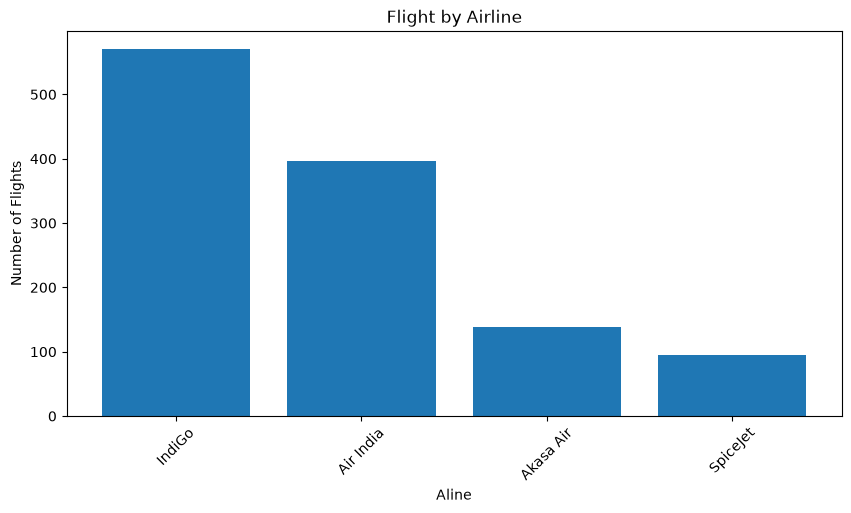

In [28]:
# How many flights are operated by each airline?



import matplotlib.pyplot as plt

airline_counts = flights["Airline"].value_counts()

plt.figure(figsize=(10,5))
plt.bar(airline_counts.index, airline_counts.values)


plt.title("Flight by Airline")
plt.xlabel("Aline")
plt.ylabel("Number of Flights")
plt.xticks(rotation = 45)
plt.show()

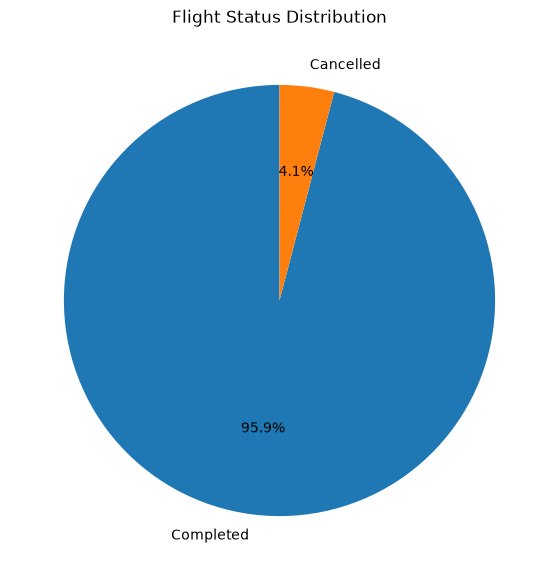

In [29]:
# What is the distribution of Completed and Cancelled flights?



status_counts = flights["Status"].value_counts()

plt.figure(figsize=(7,7))

plt.pie(

status_counts.values,
labels = status_counts.index,            
autopct = "%1.1f%%",                       # % = start of formatting  
                                           # 1 = Minimum field width
                                           # .1 = show 1 digit after decimal
                                           # f = floating-point number
                                           # %% = display the % symbol


startangle = 90 )

plt.title("Flight Status Distribution")
plt.show()

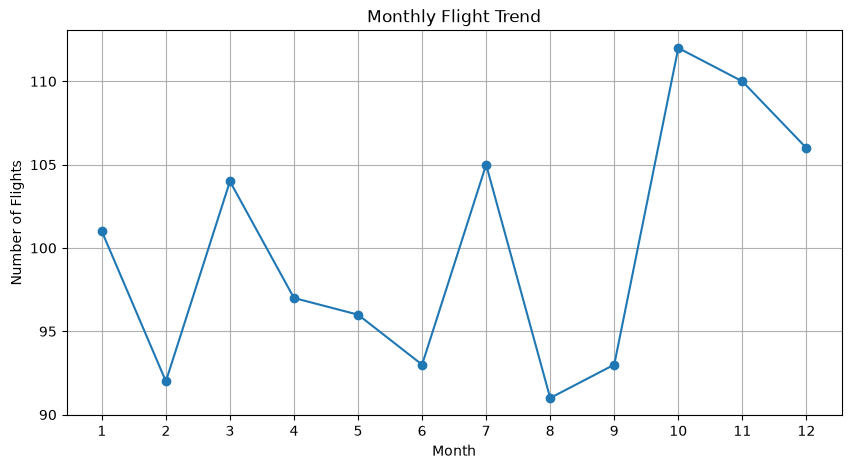

In [30]:
# How many flights operate each month?


flights["Flight_Date"] = pd.to_datetime(flights["Flight_Date"])

monthly_flights = (
    flights.groupby(flights["Flight_Date"].dt.month).size())


plt.figure(figsize=(10,5))
plt.plot(
    monthly_flights.index,
    monthly_flights.values,
    marker="o" )


plt.title("Monthly Flight Trend")
plt.xlabel("Month")
plt.ylabel("Number of Flights")
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()
    

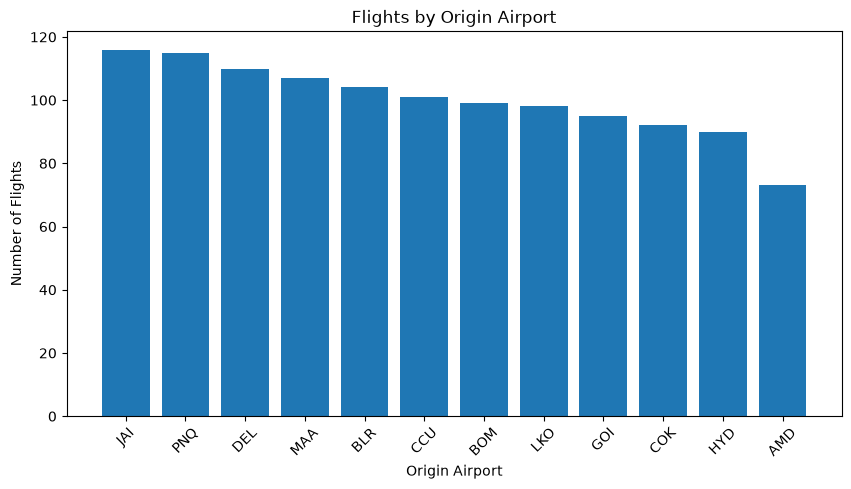

In [31]:
# Which origin airport has the highest number of flights?

origin_counts = flights["Origin"].value_counts()


plt.figure(figsize=(10,5))
plt.bar(origin_counts.index, origin_counts.values)


plt.title("Flights by Origin Airport")
plt.xlabel("Origin Airport")
plt.ylabel("Number of Flights")
plt.xticks(rotation=45)
plt.show()

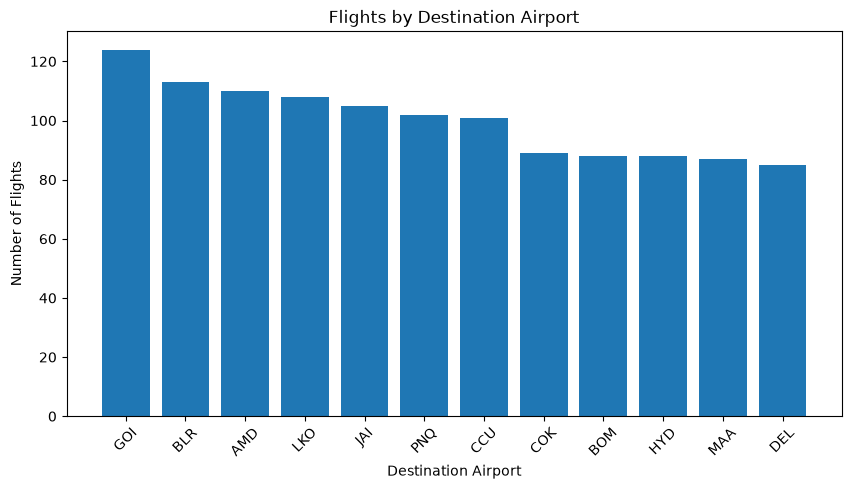

In [32]:
# Which destination airport has the highest number of flights?



destination_counts = flights["Destination"].value_counts()

plt.figure(figsize=(10,5))
plt.bar(destination_counts.index, destination_counts.values)

plt.title("Flights by Destination Airport")
plt.xlabel("Destination Airport")
plt.ylabel("Number of Flights")
plt.xticks(rotation=45)
plt.show()

In [33]:
# What are the top 10 most popular flight routes?

flights["Route"] = (                             # create Route
    flights["Origin"] + "->" + flights["Destination"] )

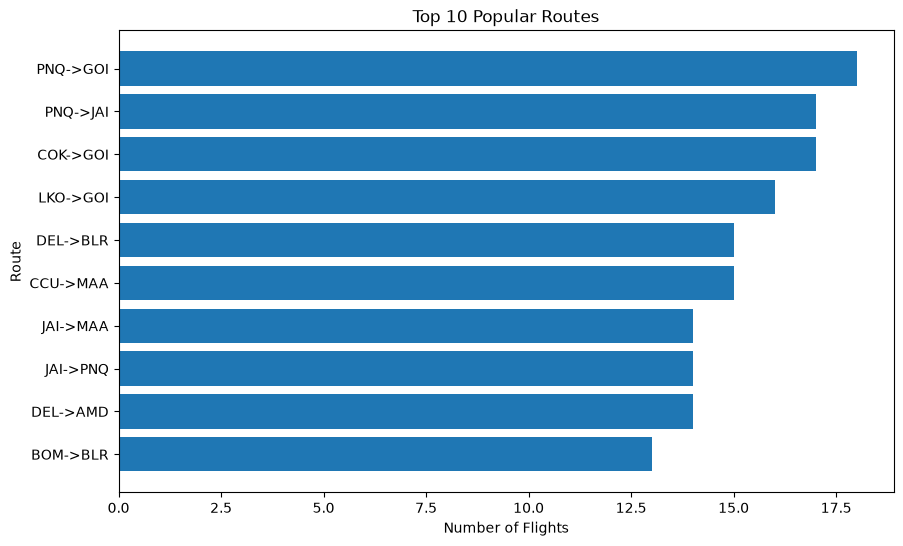

In [34]:
top_routes = flights["Route"].value_counts().head(10)


plt.figure(figsize=(10,6))
plt.barh(top_routes.index, top_routes.values)

plt.title("Top 10 Popular Routes")
plt.xlabel("Number of Flights")
plt.ylabel("Route")
plt.gca().invert_yaxis()              # gca means get current axes

plt.show()

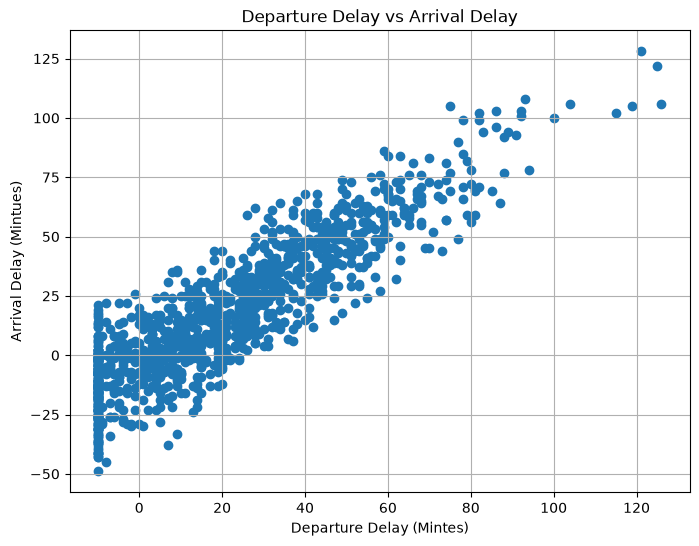

In [35]:
# Is there a relationship between departure delay and arrival delay?


delay_data = flights.dropna(
    subset=["Departure_Delay_Min", "Arrival_Delay_Min"] )

plt.figure(figsize=(8,6))

plt.scatter(
    delay_data["Departure_Delay_Min"],
    delay_data["Arrival_Delay_Min"] )


plt.title("Departure Delay vs Arrival Delay")
plt.xlabel("Departure Delay (Mintes)")
plt.ylabel("Arrival Delay (Mintues)")
plt.grid(True)
plt.show()
    

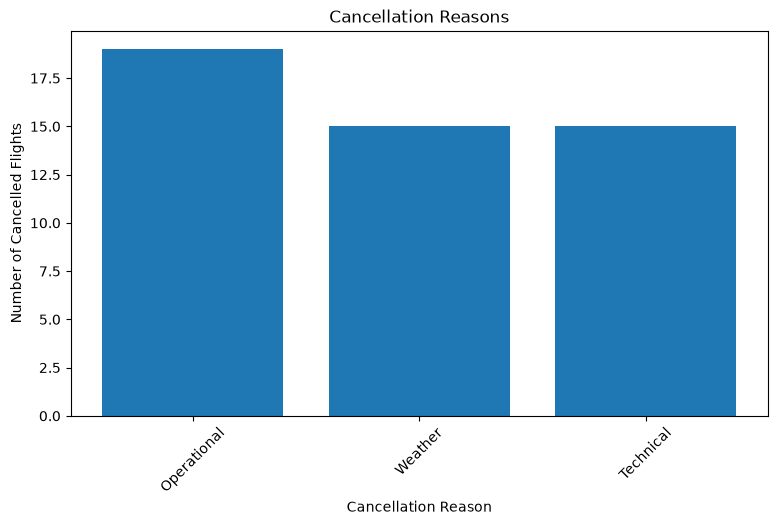

In [37]:
# Which cancellation reasons occur most frequently?

cancelled = flights[
    flights["Status"] == "Cancelled"
]

reasons = cancelled["Cancellation_Reason"].value_counts()

plt.figure(figsize=(9,5))
plt.bar(reasons.index, reasons.values)

plt.title("Cancellation Reasons")
plt.xlabel("Cancellation Reason")
plt.ylabel("Number of Cancelled Flights")
plt.xticks(rotation=45)

plt.show()